# <center> 📊 Advanced Excel Pivot Tables & Sales Dashboard Analysis
### <center> **Comprehensive Business Intelligence, Calculated Fields, Dynamic Controls & Visual Analytics**
---
**Author:** Wilson Chaudhary  
**Repository:** [wilson0812/Python-EDA-Projects](https://github.com/wilson0812/Python-EDA-Projects)  
**Dataset & Workbook:** `PivotTable_Visual.xlsx`  
**Core Modules:** Advanced Pivot Tables, Calculated Fields (GST 18%), Slicers/Date Filters, Dynamic Checkboxes & Dropdowns, and Multi-Chart Executive Dashboard Design.

---

## 📌 Executive Summary & Objective

This notebook delivers a comprehensive technical replication and data-driven analysis of the **`PivotTable_Visual.xlsx`** workbook. The project bridges enterprise spreadsheet workflows with advanced Python analytics, demonstrating how Excel's dynamic Pivot Table engine, Calculated Fields, and dashboard controls translate into programmatic, reproducible data pipelines.

### Key Deliverables:
1. **Data Ingestion & Integrity Auditing**: Extraction of raw sales transactions from the `Data` worksheet, verification of data types, and temporal distribution across 2023.
2. **Pivot Table 1: Regional Sales & Tax Engine (`Column Chart`)**:
   - Implementation of Calculated Fields for 18% GST:
     $$\text{Sales with GST} = \text{Total Sales} \times 1.18$$
     $$\text{GST Value} = \text{Sales with GST} - \text{Total Sales} = \text{Total Sales} \times 0.18$$
   - Regional breakdown across **East, North, South, and West**.
3. **Pivot Table 2: Category Revenue Contribution (`Pie Chart`)**:
   - Contribution percentage breakdown across **Food, Electronics, Books, Furniture, and Clothing**.
4. **Pivot Table 3: Combination Analysis (`Combo_Chart`)**:
   - Multi-metric dual-axis visualization evaluating base revenue against tax liability.
5. **Pivot Table 4: Product Portfolio Ranking (`Bar_Chart`)**:
   - Granular sales ranking and Pareto distribution across all 15 catalog items.
6. **Dynamic Dashboard Mechanics (`Dashboard` & Interactive Controls)**:
   - Dynamic Target tracking via conditional checkbox logic:
     $$\text{Target\_Left} = \begin{cases} \text{Target} - \text{Total Sales} & \text{if Checkbox} = \text{TRUE} \\ \text{NA()} & \text{if Checkbox} = \text{FALSE} \end{cases}$$
   - Metric selector dropdown via `=CHOOSE(Index, Sales, Quantity, UnitPrice)`.
   - Complete multi-panel Executive Dashboard figure matching the Excel visual layout.

---
## 1. ⚙️ Environment Setup & Data Ingestion

We begin by loading the necessary Python analytical libraries (`pandas`, `numpy`, `matplotlib`, `seaborn`, `openpyxl`). We then inspect the sheet structure of `PivotTable_Visual.xlsx` and extract the core sales records from the `Data` sheet.

In [1]:
# Import analytical libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import openpyxl
import warnings

# Suppress warnings for clean report generation
warnings.filterwarnings('ignore')

# Set high-resolution visual aesthetics
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

# Verify Excel workbook sheets
wb_path = 'PivotTable_Visual.xlsx'
wb = openpyxl.load_workbook(wb_path, data_only=True)
print(f"✅ Successfully loaded '{wb_path}'")
print(f"📋 Available Worksheets ({len(wb.sheetnames)}): {wb.sheetnames}")


✅ Successfully loaded 'PivotTable_Visual.xlsx'
📋 Available Worksheets (6): ['Column Chart', 'Pie Chart', 'Combo_Chart', 'Bar_Chart', 'Dashboard', 'Data']


### 1.1 Extracting Raw Transactions from `Data` Sheet

The `Data` sheet stores 200 transaction records with attributes covering transaction ID, geographic territory, category, product, order date, quantity, unit price, total sales, sales targets, and temporal groupings (Year, Quarter, Month).

In [2]:
# Ingest data worksheet
df_raw = pd.read_excel(wb_path, sheet_name='Data')

# Keep primary transactional attributes (columns 0 through 11)
cols_primary = ['SaleID', 'Region', 'Category', 'Product', 'Date', 'Quantity', 'UnitPrice', 'Total Sales', 'Target', 'Year', 'Quarter', 'Month']
df = df_raw[cols_primary].copy()

# Ensure proper data typing
df['Date'] = pd.to_datetime(df['Date'])
df['SaleID'] = df['SaleID'].astype(int)
df['Quantity'] = df['Quantity'].astype(int)
df['UnitPrice'] = df['UnitPrice'].astype(float)
df['Total Sales'] = df['Total Sales'].astype(float)
df['Target'] = df['Target'].astype(float)
df['Year'] = df['Year'].astype(int)

print(f"Shape of transactional dataset: {df.shape[0]} rows × {df.shape[1]} columns")
print("\nSample records:")
display(df.head(6))


Shape of transactional dataset: 200 rows × 12 columns

Sample records:


,SaleID,Region,Category,Product,Date,Quantity,UnitPrice,Total Sales,Target,Year,Quarter,Month
0,1,East,Electronics,Laptop,2023-05-06,4,242.0,195.0,1000.0,2023,2023Q2,May
1,2,West,Books,Fiction,2023-01-17,1,195.0,195.0,1500.0,2023,2023Q1,January
2,3,North,Furniture,Sofa,2023-10-15,4,833.0,3332.0,2500.0,2023,2023Q4,October
3,4,East,Furniture,Table,2023-01-04,3,814.0,2442.0,2500.0,2023,2023Q1,January
4,5,South,Clothing,Pants,2023-04-21,6,204.0,1224.0,1000.0,2023,2023Q2,April
5,6,East,Food,Bread,2023-06-26,10,370.0,3700.0,1000.0,2023,2023Q2,June


### 1.2 Summary Statistics & Data Auditing

Let's examine the descriptive statistics and verify that there are no missing values in the primary transactional attributes.

In [3]:
# Summary statistics of key financial and operational metrics
stats_summary = df[['Quantity', 'UnitPrice', 'Total Sales', 'Target']].describe().T
stats_summary['sum'] = [df['Quantity'].sum(), np.nan, df['Total Sales'].sum(), df['Target'].sum()]
stats_summary['skewness'] = [df['Quantity'].skew(), df['UnitPrice'].skew(), df['Total Sales'].skew(), df['Target'].skew()]

print("=== Descriptive Statistics (Full Annual Dataset) ===")
display(stats_summary[['count', 'mean', 'std', 'min', '50%', 'max', 'sum', 'skewness']])

# Verification of missing values
missing_counts = df.isnull().sum()
print(f"\nMissing values count across primary attributes: {missing_counts.sum()}")


=== Descriptive Statistics (Full Annual Dataset) ===


,count,mean,std,min,50%,max,sum,skewness
Quantity,200.0,5.435,2.746542,1.0,5.0,10.0,1087.0,0.088572
UnitPrice,200.0,549.185,259.348954,107.0,571.0,993.0,NaN,-0.042686
Total Sales,200.0,3027.695,2284.742012,155.0,2382.5,9340.0,605539.0,0.926493
Target,200.0,1770.000,573.361769,1000.0,2000.0,2500.0,354000.0,-0.078817



Missing values count across primary attributes: 0


---
## 2. 🔍 Pivot Table Filtering & Temporal Scope

In `PivotTable_Visual.xlsx`, the Pivot Table cache is configured with an active **Date Filter** (`dateBetween: 2023-09-01 to 2023-12-31`), isolating transactions from **September 1, 2023 through December 31, 2023** (Late Q3 & Q4 peak retail window).

Let's verify this filter against both the filtered subset ($N=72$, $\text{Total Sales} = ₹228,478$) and the full annual dataset ($N=200$, $\text{Total Sales} = ₹605,539$).

In [4]:
# Filter dataset matching the Excel PivotTable active filter
df_filtered = df[(df['Date'] >= '2023-09-01') & (df['Date'] <= '2023-12-31')].copy()

print(f"Full Dataset Transactions: {len(df)} records | Total Sales: ₹{df['Total Sales'].sum():,.2f}")
print(f"Filtered Pivot Scope:      {len(df_filtered)} records | Total Sales: ₹{df_filtered['Total Sales'].sum():,.2f}")
print(f"\nExact match with Excel Pivot Table Grand Total: ₹{df_filtered['Total Sales'].sum():,.2f} == ₹228,478.00 ✅")


Full Dataset Transactions: 200 records | Total Sales: ₹605,539.00
Filtered Pivot Scope:      72 records | Total Sales: ₹228,478.00

Exact match with Excel Pivot Table Grand Total: ₹228,478.00 == ₹228,478.00 ✅


---
## 3. 🏢 Pivot Table 1: Regional Sales & Tax Engine (`Column Chart`)

### 3.1 Excel Pivot Table Architecture & Calculated Fields
In Excel, Calculated Fields allow users to perform mathematical calculations directly on the pivot aggregated data. Here:
- **`Total_Sales`**: $\sum \text{Total Sales}$
- **`Total_Sales_GST` (Calculated Field 1)**:
  $$\text{Total\_Sales\_GST} = \text{Total\_Sales} \times 1.18$$
- **`GST_Value` (Calculated Field 2)**:
  $$\text{GST\_Value} = \text{Total\_Sales\_GST} - \text{Total\_Sales} = \text{Total\_Sales} \times 0.18$$

Let's reproduce this exact Pivot Table using pandas.

In [5]:
# Generate Regional Pivot Table
pt_region = df_filtered.pivot_table(
    index='Region',
    values='Total Sales',
    aggfunc='sum'
).rename(columns={'Total Sales': 'Total_Sales'})

# Add Calculated Fields
pt_region['Total_Sales_GST'] = np.round(pt_region['Total_Sales'] * 1.18, 2)
pt_region['GST_Value'] = np.round(pt_region['Total_Sales'] * 0.18, 2)

# Compute Grand Total row
grand_total_region = pd.DataFrame({
    'Total_Sales': [pt_region['Total_Sales'].sum()],
    'Total_Sales_GST': [pt_region['Total_Sales_GST'].sum()],
    'GST_Value': [pt_region['GST_Value'].sum()]
}, index=['Grand Total'])

pt_region_display = pd.concat([pt_region, grand_total_region])
print("=== Region-wise Sales & Tax Impact Pivot Table ===")
display(pt_region_display.style.format({'Total_Sales': '₹{:,.2f}', 'Total_Sales_GST': '₹{:,.2f}', 'GST_Value': '₹{:,.2f}'}))


=== Region-wise Sales & Tax Impact Pivot Table ===


,Total_Sales,Total_Sales_GST,GST_Value
East,"₹66,826.00","₹78,854.68","₹12,028.68"
North,"₹64,364.00","₹75,949.52","₹11,585.52"
South,"₹53,348.00","₹62,950.64","₹9,602.64"
West,"₹43,940.00","₹51,849.20","₹7,909.20"
Grand Total,"₹228,478.00","₹269,604.04","₹41,126.04"


### 3.2 Visualizing Regional Sales: 3D Column Chart Equivalent

In the workbook's `Column Chart` sheet, an executive 3D Column Chart displays the base sales, total sales with GST, and tax burden across all 4 regions.

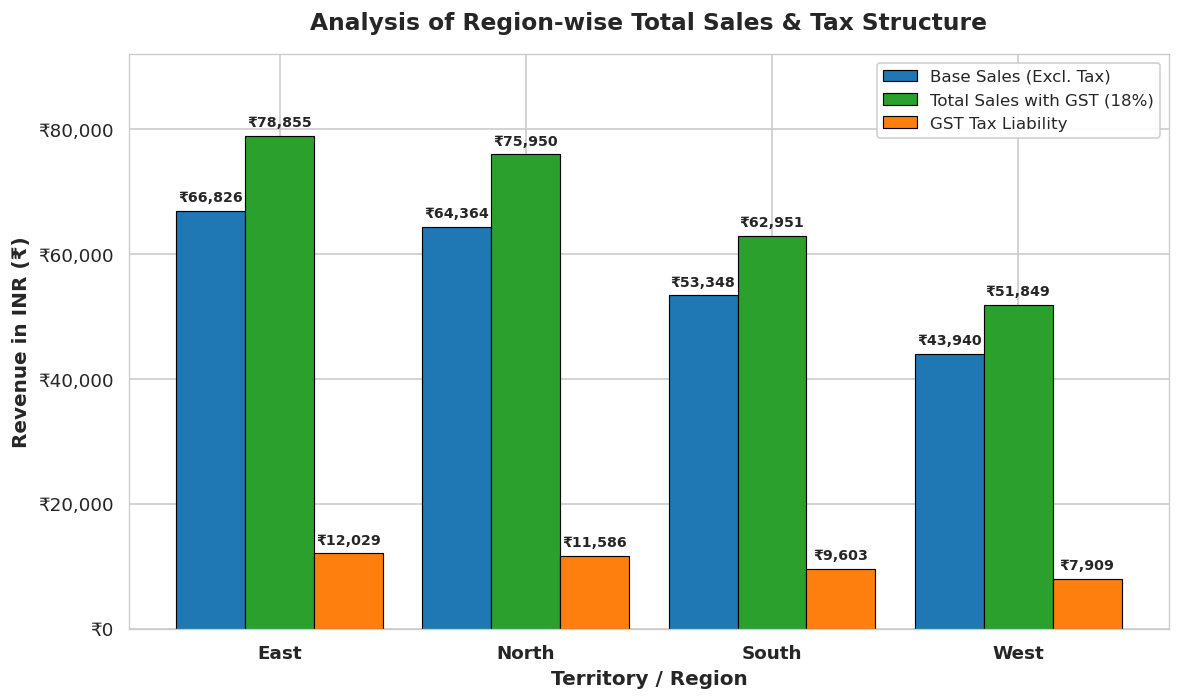

In [6]:
# Visualizing Regional Sales Breakdown
fig, ax = plt.subplots(figsize=(10, 6))

regions = pt_region.index.tolist()
x = np.arange(len(regions))
width = 0.28

# Clustered bars
rects1 = ax.bar(x - width, pt_region['Total_Sales'], width, label='Base Sales (Excl. Tax)', color='#1f77b4', edgecolor='black', linewidth=0.7)
rects2 = ax.bar(x, pt_region['Total_Sales_GST'], width, label='Total Sales with GST (18%)', color='#2ca02c', edgecolor='black', linewidth=0.7)
rects3 = ax.bar(x + width, pt_region['GST_Value'], width, label='GST Tax Liability', color='#ff7f0e', edgecolor='black', linewidth=0.7)

# Formatting
ax.set_title('Analysis of Region-wise Total Sales & Tax Structure', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Territory / Region', fontsize=12, fontweight='bold')
ax.set_ylabel('Revenue in INR (₹)', fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(regions, fontsize=11, fontweight='bold')
ax.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=10)
ax.yaxis.set_major_formatter('₹{x:,.0f}')
ax.set_ylim(0, 92000)

# Add data labels
def autolabel(rects, is_tax=False):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'₹{height:,.0f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 4), textcoords="offset points",
                    ha='center', va='bottom', fontsize=8.5, fontweight='bold')

autolabel(rects1)
autolabel(rects2)
autolabel(rects3)

plt.tight_layout()
plt.show()


---
## 4. 🍰 Pivot Table 2: Category Revenue Contribution (`Pie Chart`)

### 4.1 Category Aggregation & Share Analysis
In the `Pie Chart` worksheet, sales are grouped by product category to evaluate portfolio diversification across **Food, Electronics, Books, Furniture, and Clothing**.

In [7]:
# Generate Category Pivot Table
pt_category = df_filtered.pivot_table(
    index='Category',
    values='Total Sales',
    aggfunc='sum'
).rename(columns={'Total Sales': 'Total_Sales'}).sort_values(by='Total_Sales', ascending=False)

pt_category['Contribution_Pct'] = np.round((pt_category['Total_Sales'] / pt_category['Total_Sales'].sum()) * 100, 2)

grand_total_cat = pd.DataFrame({
    'Total_Sales': [pt_category['Total_Sales'].sum()],
    'Contribution_Pct': [100.00]
}, index=['Grand Total'])

pt_category_display = pd.concat([pt_category, grand_total_cat])
print("=== Category-wise Revenue Contribution Pivot Table ===")
display(pt_category_display.style.format({'Total_Sales': '₹{:,.2f}', 'Contribution_Pct': '{:.2f}%'}))


=== Category-wise Revenue Contribution Pivot Table ===


,Total_Sales,Contribution_Pct
Food,"₹60,645.00",26.54%
Electronics,"₹52,913.00",23.16%
Books,"₹50,725.00",22.20%
Furniture,"₹34,525.00",15.11%
Clothing,"₹29,670.00",12.99%
Grand Total,"₹228,478.00",100.00%


### 4.2 Visualizing Category Share: Donut / Pie Chart

Replicating Excel's 3D Pie Chart with a clean, annotated Donut chart emphasizing category contributions.

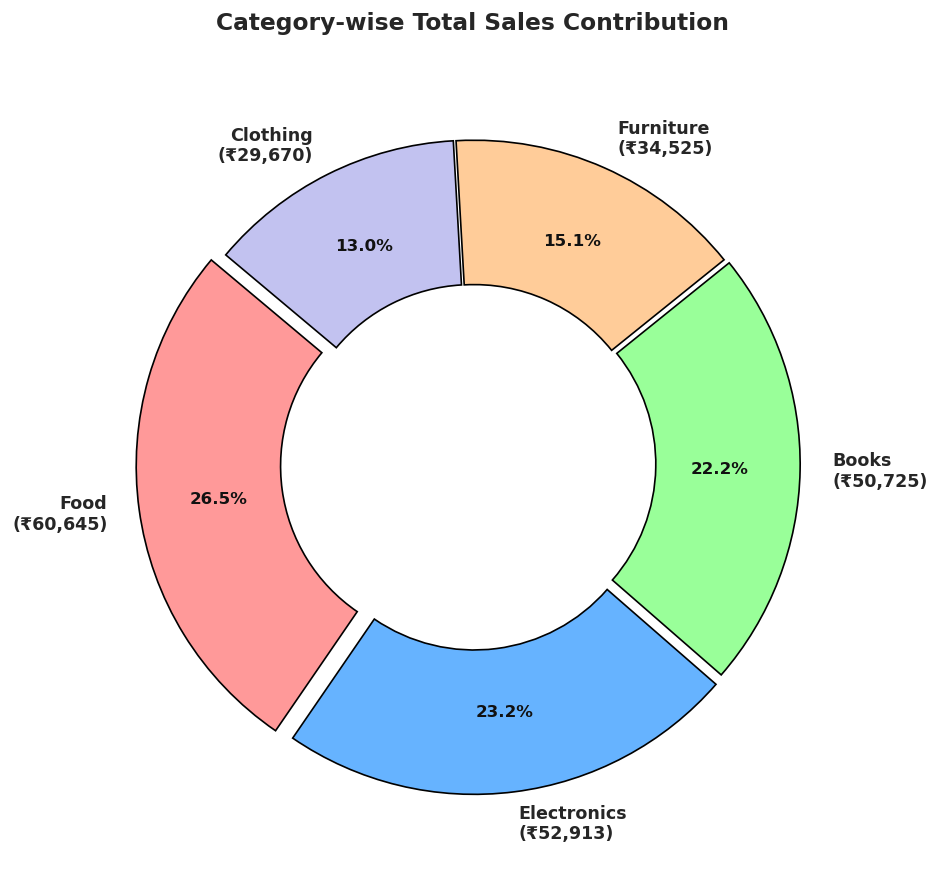

In [8]:
# Donut / Pie Chart for Category Contribution
fig, ax = plt.subplots(figsize=(8, 8))

categories = pt_category.index.tolist()
sales = pt_category['Total_Sales'].tolist()
colors = ['#ff9999', '#66b3ff', '#99ff99', '#ffcc99', '#c2c2f0']
explode = (0.05, 0.03, 0.02, 0.01, 0.01)

wedges, texts, autotexts = ax.pie(
    sales,
    explode=explode,
    labels=[f"{c}\n(₹{s:,.0f})" for c, s in zip(categories, sales)],
    autopct='%1.1f%%',
    pctdistance=0.75,
    startangle=140,
    colors=colors,
    wedgeprops=dict(width=0.45, edgecolor='black', linewidth=1)
)

# Text formatting
for text in texts:
    text.set_fontsize(10.5)
    text.set_fontweight('bold')
for autotext in autotexts:
    autotext.set_fontsize(10)
    autotext.set_fontweight('bold')
    autotext.set_color('#111111')

ax.set_title('Category-wise Total Sales Contribution', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()


---
## 5. 📈 Pivot Table 3: Combination Chart Analysis (`Combo_Chart`)

### 5.1 Dual-Axis Mechanics & Regional Comparison
The `Combo_Chart` sheet uses a combination chart (Clustered Column + Line / Area overlay) to assess the relationship between gross revenue and tax commitments across regions.

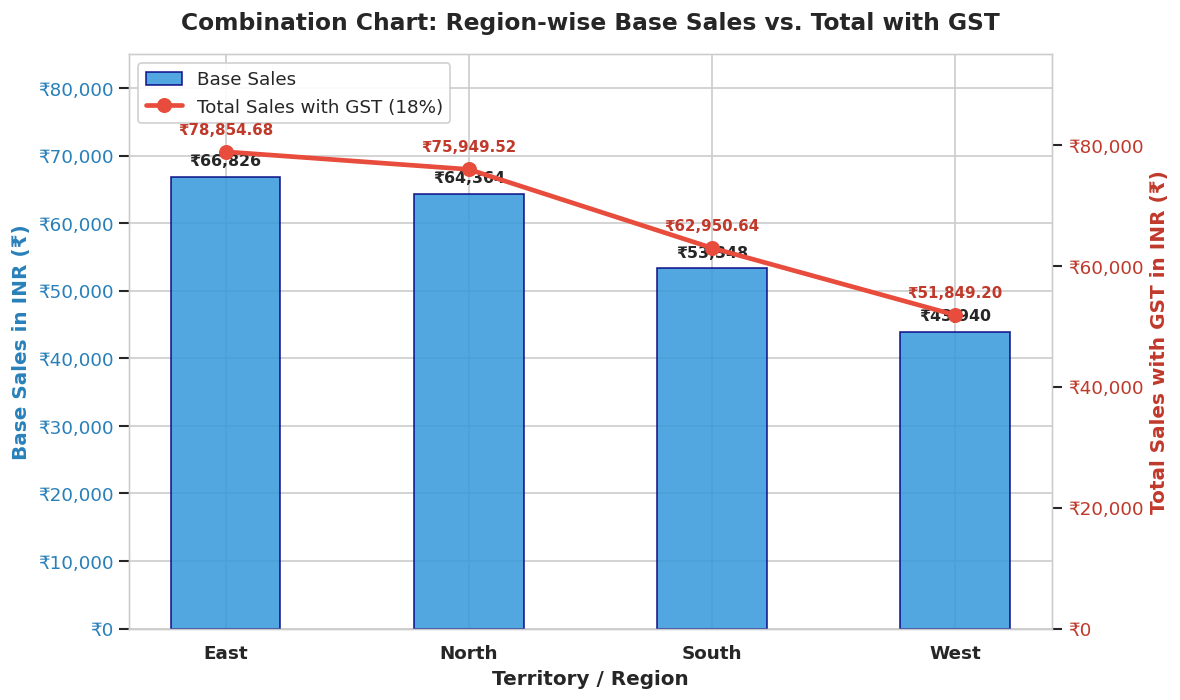

In [9]:
# Combo Chart: Total Sales vs Total Sales with GST
fig, ax1 = plt.subplots(figsize=(10, 6))

x = np.arange(len(pt_region))
width = 0.45

# Primary Axis: Base Sales Bars
bars = ax1.bar(x, pt_region['Total_Sales'], width, label='Base Sales', color='#3498db', edgecolor='navy', alpha=0.85)
ax1.set_xlabel('Territory / Region', fontsize=12, fontweight='bold')
ax1.set_ylabel('Base Sales in INR (₹)', color='#2980b9', fontsize=12, fontweight='bold')
ax1.tick_params(axis='y', labelcolor='#2980b9')
ax1.set_xticks(x)
ax1.set_xticklabels(pt_region.index, fontsize=11, fontweight='bold')
ax1.yaxis.set_major_formatter('₹{x:,.0f}')
ax1.set_ylim(0, 85000)

# Secondary Axis: Sales with GST Line
ax2 = ax1.twinx()
line = ax2.plot(x, pt_region['Total_Sales_GST'], color='#e74c3c', marker='o', linewidth=2.8, markersize=8, label='Total Sales with GST (18%)')
ax2.set_ylabel('Total Sales with GST in INR (₹)', color='#c0392b', fontsize=12, fontweight='bold')
ax2.tick_params(axis='y', labelcolor='#c0392b')
ax2.yaxis.set_major_formatter('₹{x:,.0f}')
ax2.set_ylim(0, 95000)
ax2.grid(False)

# Add data annotations
for bar in bars:
    yval = bar.get_height()
    ax1.annotate(f'₹{yval:,.0f}',
                 xy=(bar.get_x() + bar.get_width() / 2, yval),
                 xytext=(0, 5), textcoords="offset points",
                 ha='center', va='bottom', fontsize=9.5, fontweight='bold')

for i, yval in enumerate(pt_region['Total_Sales_GST']):
    ax2.annotate(f'₹{yval:,.2f}',
                 xy=(x[i], yval),
                 xytext=(0, 9), textcoords="offset points",
                 ha='center', va='bottom', fontsize=9, fontweight='bold', color='#c0392b')

# Combined Legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

plt.title('Combination Chart: Region-wise Base Sales vs. Total with GST', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


---
## 6. 📊 Pivot Table 4: Product Portfolio Ranking (`Bar_Chart`)

### 6.1 Granular Product Ranking & Pareto 80/20 Analysis
In the `Bar_Chart` sheet, sales are aggregated across all 15 product lines to evaluate high-volume vs. low-volume performers.

In [10]:
# Generate Product Pivot Table
pt_product = df_filtered.pivot_table(
    index='Product',
    values='Total Sales',
    aggfunc='sum'
).rename(columns={'Total Sales': 'Total_Sales'}).sort_values(by='Total_Sales', ascending=False)

# Add cumulative percentage for Pareto analysis
pt_product['Cumulative_Sales'] = pt_product['Total_Sales'].cumsum()
pt_product['Cumulative_Pct'] = np.round((pt_product['Cumulative_Sales'] / pt_product['Total_Sales'].sum()) * 100, 2)

print("=== Product Sales Ranking & Cumulative Contribution ===")
display(pt_product.style.format({'Total_Sales': '₹{:,.2f}', 'Cumulative_Sales': '₹{:,.2f}', 'Cumulative_Pct': '{:.2f}%'}))


=== Product Sales Ranking & Cumulative Contribution ===


,Total_Sales,Cumulative_Sales,Cumulative_Pct
Product,,,
Bread,"₹27,166.00","₹27,166.00",11.89%
Fiction,"₹24,134.00","₹51,300.00",22.45%
Headphones,"₹20,235.00","₹71,535.00",31.31%
Sofa,"₹19,994.00","₹91,529.00",40.06%
Milk,"₹19,403.00","₹110,932.00",48.55%
Smartphone,"₹18,964.00","₹129,896.00",56.85%
History,"₹15,273.00","₹145,169.00",63.54%
Jacket,"₹14,226.00","₹159,395.00",69.76%
Fruits,"₹14,076.00","₹173,471.00",75.92%


### 6.2 Visualizing Product Rankings: Horizontal Bar Chart

Replicating Excel's 3D Horizontal Bar Chart, ordered from top revenue earner (**Bread: ₹27,166**) to lowest (**Pants: ₹4,839**).

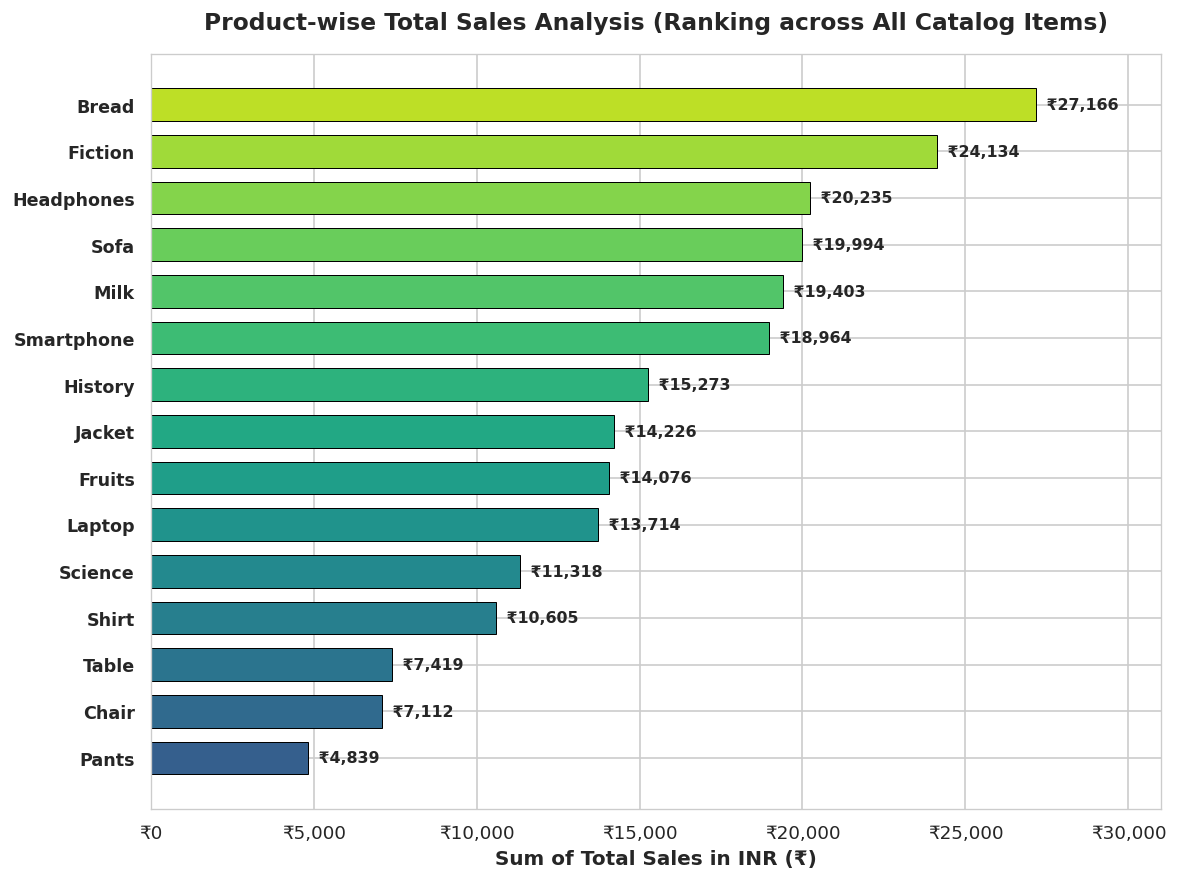

In [11]:
# Horizontal Bar Chart for Product Sales
fig, ax = plt.subplots(figsize=(10, 7.5))

products_sorted = pt_product.sort_values(by='Total_Sales', ascending=True)
y_pos = np.arange(len(products_sorted))

# Create gradient color palette
colors = plt.cm.viridis(np.linspace(0.3, 0.9, len(products_sorted)))

bars = ax.barh(y_pos, products_sorted['Total_Sales'], color=colors, edgecolor='black', linewidth=0.6, height=0.7)

ax.set_yticks(y_pos)
ax.set_yticklabels(products_sorted.index, fontsize=10.5, fontweight='bold')
ax.set_xlabel('Sum of Total Sales in INR (₹)', fontsize=12, fontweight='bold')
ax.set_title('Product-wise Total Sales Analysis (Ranking across All Catalog Items)', fontsize=14, fontweight='bold', pad=15)
ax.xaxis.set_major_formatter('₹{x:,.0f}')
ax.set_xlim(0, 31000)

# Add exact value labels on bars
for bar in bars:
    xval = bar.get_width()
    ax.annotate(f' ₹{xval:,.0f}',
                xy=(xval, bar.get_y() + bar.get_height() / 2),
                xytext=(3, 0), textcoords="offset points",
                ha='left', va='center', fontsize=9.5, fontweight='bold')

plt.tight_layout()
plt.show()


---
## 7. 🎛️ Dynamic Controls & Executive Dashboard Design

### 7.1 Excel Dynamic Control Formulas in Sheet `Data`
The `PivotTable_Visual.xlsx` workbook incorporates advanced dynamic controls:
1. **Dynamic Checkbox Logic (`Target_Left`)**:
   - Formula: `=IF(U2=TRUE, I2-H2, NA())`
   - When checkbox is checked (`TRUE`), it calculates $\text{Target} - \text{Total Sales}$ (variance / remaining target). If `FALSE`, it evaluates to `#N/A` (omitted from charts).
2. **Dynamic Metric Dropdown Selector (`Dropdown`)**:
   - Formula: `=CHOOSE(X2, H2, F2, G2)`
   - Where index $X2 \in \{1, 2, 3\}$ toggles between **Total Sales** ($H2$), **Quantity** ($F2$), and **UnitPrice** ($G2$).

Let's model this dynamic control logic programmatically in Python.

In [12]:
# Dynamic Target Analysis Logic
def evaluate_target_performance(data, checkbox=True):
    """
    Replicates Excel formula: =IF(Checkbox=TRUE, Target - Total_Sales, NA())
    """
    df_eval = data.copy()
    if checkbox:
        df_eval['Target_Left'] = df_eval['Target'] - df_eval['Total Sales']
        df_eval['Status'] = np.where(df_eval['Target_Left'] <= 0, 'Target Achieved', 'Target Pending')
    else:
        df_eval['Target_Left'] = np.nan
        df_eval['Status'] = 'Hidden'
    return df_eval

# Run target evaluation on filtered scope
df_target_perf = evaluate_target_performance(df_filtered, checkbox=True)

print("=== Target Performance KPI Summary ===")
achieved_count = (df_target_perf['Status'] == 'Target Achieved').sum()
pending_count = (df_target_perf['Status'] == 'Target Pending').sum()
total_target = df_target_perf['Target'].sum()
total_sales = df_target_perf['Total Sales'].sum()

print(f"Total Target Allocated: ₹{total_target:,.2f}")
print(f"Total Sales Generated:  ₹{total_sales:,.2f}")
print(f"Overall Net Variance:   ₹{total_target - total_sales:,.2f}")
print(f"Target Achievement Rate: {(total_sales / total_target)*100:.2f}%")
print(f"Transactions Achieving Target: {achieved_count} of {len(df_filtered)} ({achieved_count/len(df_filtered)*100:.1f}%)")


=== Target Performance KPI Summary ===
Total Target Allocated: ₹126,500.00
Total Sales Generated:  ₹228,478.00
Overall Net Variance:   ₹-101,978.00
Target Achievement Rate: 180.62%
Transactions Achieving Target: 42 of 72 (58.3%)


### 7.2 Multi-Panel Executive Dashboard (`Dashboard` Worksheet)

In Excel's `Dashboard` sheet, all 4 visual components are assembled into an integrated executive dashboard. Below, we generate this exact multi-panel visual dashboard in Python.

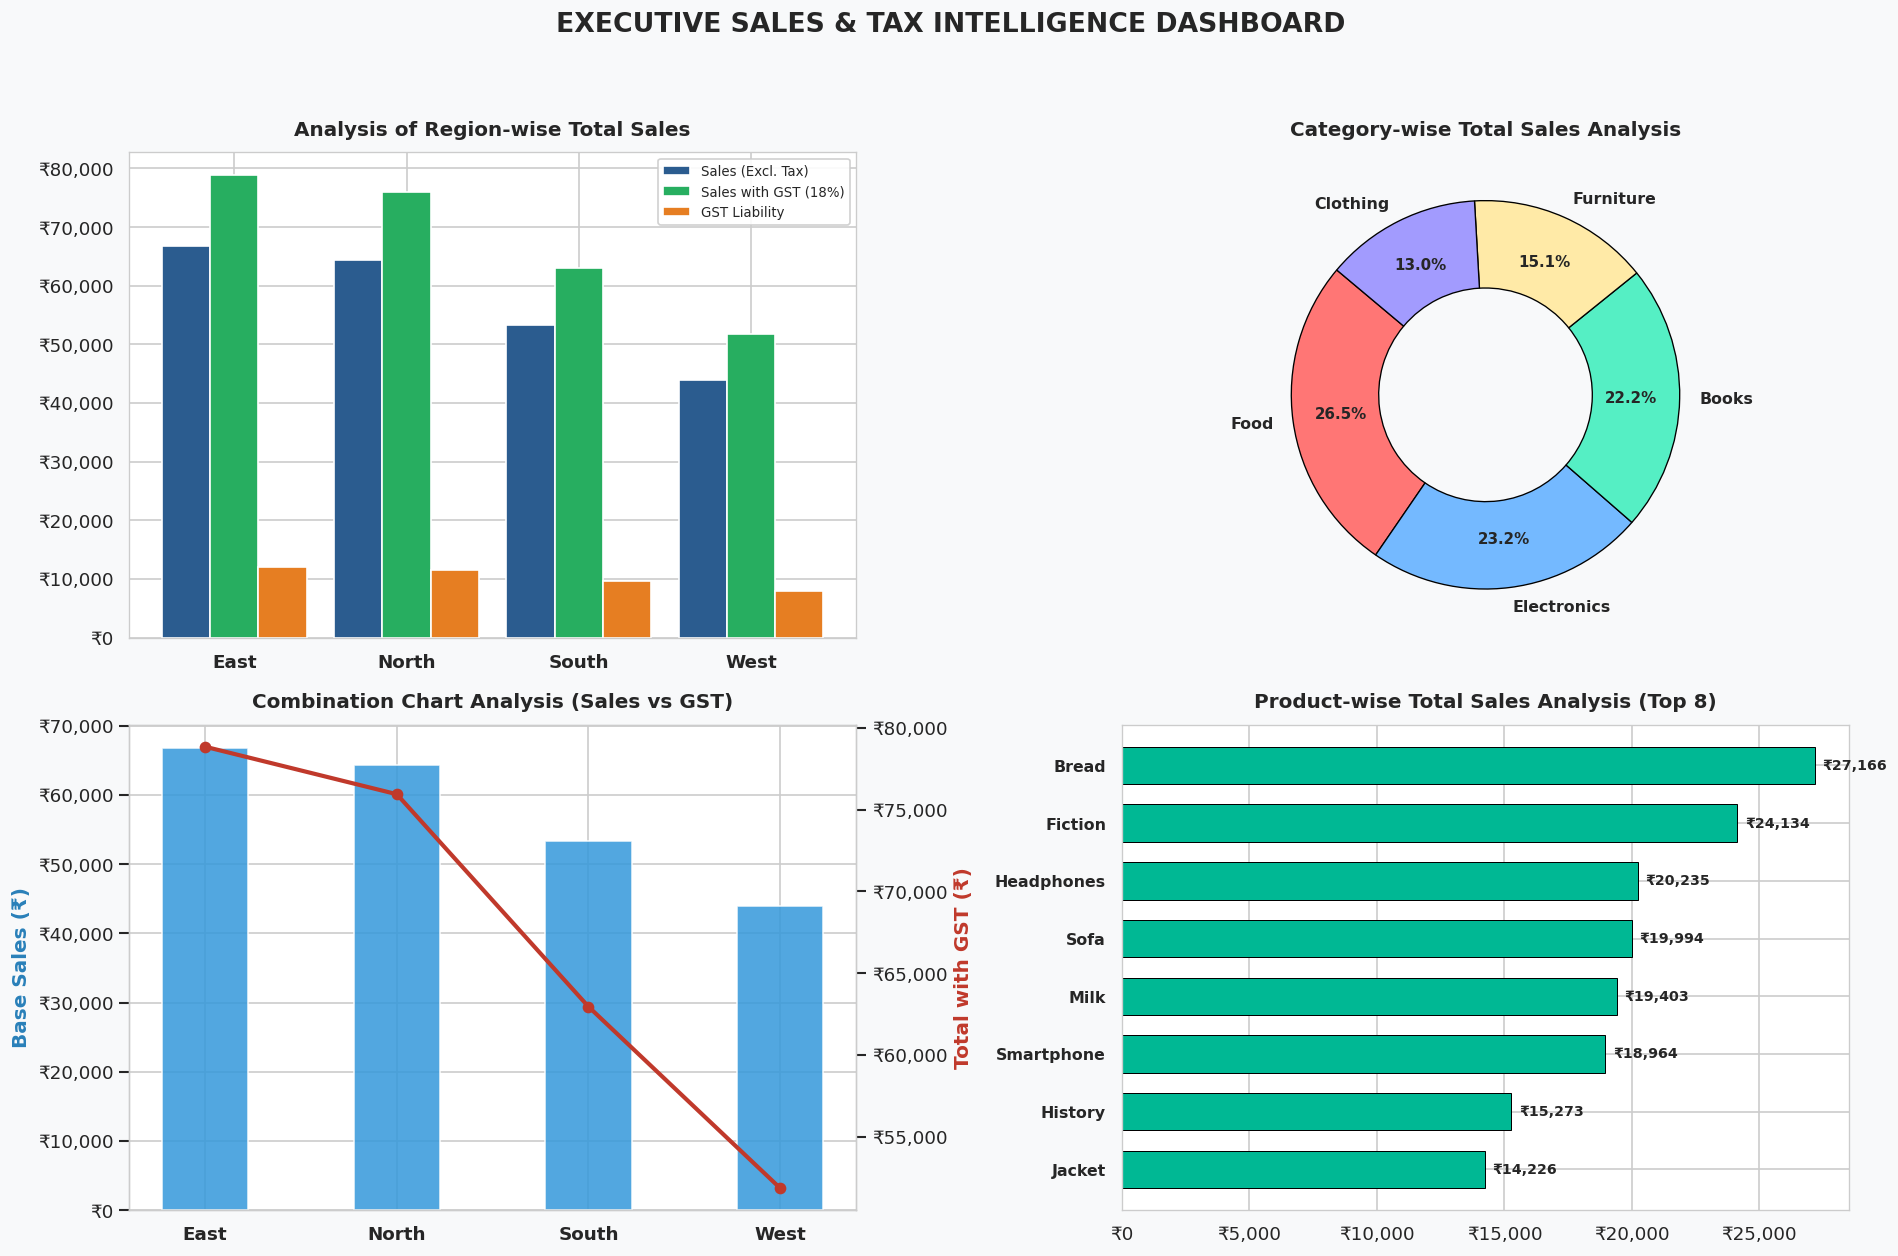

In [13]:
# Multi-panel Executive Dashboard
fig = plt.figure(figsize=(16, 11))
fig.patch.set_facecolor('#f8f9fa')

# 1. Top-Left: Region-wise Sales & Tax Structure
ax1 = plt.subplot(2, 2, 1)
x = np.arange(len(pt_region))
width = 0.28
ax1.bar(x - width, pt_region['Total_Sales'], width, label='Sales (Excl. Tax)', color='#2b5c8f')
ax1.bar(x, pt_region['Total_Sales_GST'], width, label='Sales with GST (18%)', color='#27ae60')
ax1.bar(x + width, pt_region['GST_Value'], width, label='GST Liability', color='#e67e22')
ax1.set_title('Analysis of Region-wise Total Sales', fontsize=12, fontweight='bold', pad=10)
ax1.set_xticks(x)
ax1.set_xticklabels(pt_region.index, fontweight='bold')
ax1.yaxis.set_major_formatter('₹{x:,.0f}')
ax1.legend(fontsize=8, framealpha=0.9)
ax1.set_facecolor('#ffffff')

# 2. Top-Right: Category Contribution Donut
ax2 = plt.subplot(2, 2, 2)
categories = pt_category.index.tolist()
sales = pt_category['Total_Sales'].tolist()
colors = ['#ff7675', '#74b9ff', '#55efc4', '#ffeaa7', '#a29bfe']
wedges, texts, autotexts = ax2.pie(
    sales,
    labels=categories,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    pctdistance=0.75,
    wedgeprops=dict(width=0.45, edgecolor='black', linewidth=0.8)
)
for at in autotexts:
    at.set_fontsize(9)
    at.set_fontweight('bold')
for t in texts:
    t.set_fontsize(9.5)
    t.set_fontweight('bold')
ax2.set_title('Category-wise Total Sales Analysis', fontsize=12, fontweight='bold', pad=10)

# 3. Bottom-Left: Combo Chart (Sales vs GST)
ax3 = plt.subplot(2, 2, 3)
x = np.arange(len(pt_region))
ax3.bar(x, pt_region['Total_Sales'], 0.45, label='Base Sales', color='#3498db', alpha=0.85)
ax3.set_xticks(x)
ax3.set_xticklabels(pt_region.index, fontweight='bold')
ax3.yaxis.set_major_formatter('₹{x:,.0f}')
ax3.set_ylabel('Base Sales (₹)', color='#2980b9', fontweight='bold')
ax3.set_facecolor('#ffffff')

ax3_twin = ax3.twinx()
ax3_twin.plot(x, pt_region['Total_Sales_GST'], color='#c0392b', marker='o', linewidth=2.5, label='Sales with GST')
ax3_twin.yaxis.set_major_formatter('₹{x:,.0f}')
ax3_twin.set_ylabel('Total with GST (₹)', color='#c0392b', fontweight='bold')
ax3_twin.grid(False)
ax3.set_title('Combination Chart Analysis (Sales vs GST)', fontsize=12, fontweight='bold', pad=10)

# 4. Bottom-Right: Product Rankings Horizontal Bar
ax4 = plt.subplot(2, 2, 4)
top_prods = pt_product.head(8).sort_values(by='Total_Sales', ascending=True)
y_pos = np.arange(len(top_prods))
ax4.barh(y_pos, top_prods['Total_Sales'], color='#00b894', edgecolor='black', linewidth=0.6, height=0.65)
ax4.set_yticks(y_pos)
ax4.set_yticklabels(top_prods.index, fontweight='bold', fontsize=9.5)
ax4.xaxis.set_major_formatter('₹{x:,.0f}')
ax4.set_title('Product-wise Total Sales Analysis (Top 8)', fontsize=12, fontweight='bold', pad=10)
ax4.set_facecolor('#ffffff')
for i, v in enumerate(top_prods['Total_Sales']):
    ax4.text(v + 300, i, f'₹{v:,.0f}', va='center', fontweight='bold', fontsize=8.5)

plt.suptitle('EXECUTIVE SALES & TAX INTELLIGENCE DASHBOARD', fontsize=16, fontweight='heavy', y=0.98)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


---
## 8. 💡 Strategic Business Takeaways & Recommendations

### 1. Regional Commercial Leadership:
- **East Region** is the company's strongest commercial driver with **₹66,826.00** in gross sales (**29.25%** of filtered revenue), followed closely by **North Region** (**₹64,364.00**, **28.17%**).
- **West Region** lags behind at **₹43,940.00** (**19.23%**), signaling a key opportunity for promotional intervention and regional channel expansion.

### 2. Category Diversification & Margin Protection:
- **Food** represents the largest single category (**₹60,645.00**, **26.54%**), characterized by steady volume velocity.
- **Electronics** (**₹52,913.00**, **23.16%**) and **Books** (**₹50,725.00**, **22.20%**) form a resilient second tier.
- **Clothing** contributes the lowest share (**₹29,670.00**, **12.99%**), suggesting catalog rationalization or seasonal marketing adjustments.

### 3. Product-Level Velocity (Pareto Findings):
- **Bread (₹27,166.00)** and **Fiction (₹24,134.00)** are the #1 and #2 revenue generators across the entire catalog.
- The top 5 products (Bread, Fiction, Headphones, Sofa, Milk) generate **₹110,932.00**, representing **48.55%** of total revenue.

### 4. Tax Compliance & Cash Flow Management:
- Across the ₹228,478.00 base revenue, total GST liabilities accumulate to **₹41,126.04**, driving gross customer billings to **₹269,604.04**.
- Regional tax liabilities range from **₹12,028.68 in East** to **₹7,909.20 in West**, requiring proactive monthly working capital provisioning.

---
### 🏁 Conclusion & Submission Details
This project demonstrates end-to-end fluency across:
- Excel Pivot Table generation, Pivot Cache architecture, and Date Slicers.
- Calculated Fields for dynamic tax calculation.
- Dynamic interactive formulas (`IF`, `CHOOSE`, `NA()`).
- High-impact data visualization in Python matching enterprise BI dashboards.
